In [9]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from data import GDPHMM_OAR_V3
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED

In [11]:
dataset = build_dataset('test')

In [12]:
baseline_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
fp16_train_pred = ModelResults('111-mixed-precision', 'ddpm-1000', 199, 'test', dataset)
bf16_train_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)
bf16_samp_pred = ModelResults('101-beamdiff', 'ddpm-1000-bf16-amp', 199, 'test', dataset)
fp16_samp_pred = ModelResults('101-beamdiff', 'ddpm-1000-fp16-amp', 199, 'test', dataset)
bf16_bf16_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-bf16-amp', 199, 'test', dataset)
bf16_fp16_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-fp16-amp', 199, 'test', dataset)

# Mixed Precision Training

In [13]:
training_comparison = ModelComparison(
  [baseline_pred, fp16_train_pred, bf16_train_pred],
  ['Baseline', 'FP16 AMP Training', 'BF16 AMP Training'],
)

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1002: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1002: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1002: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1002: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  


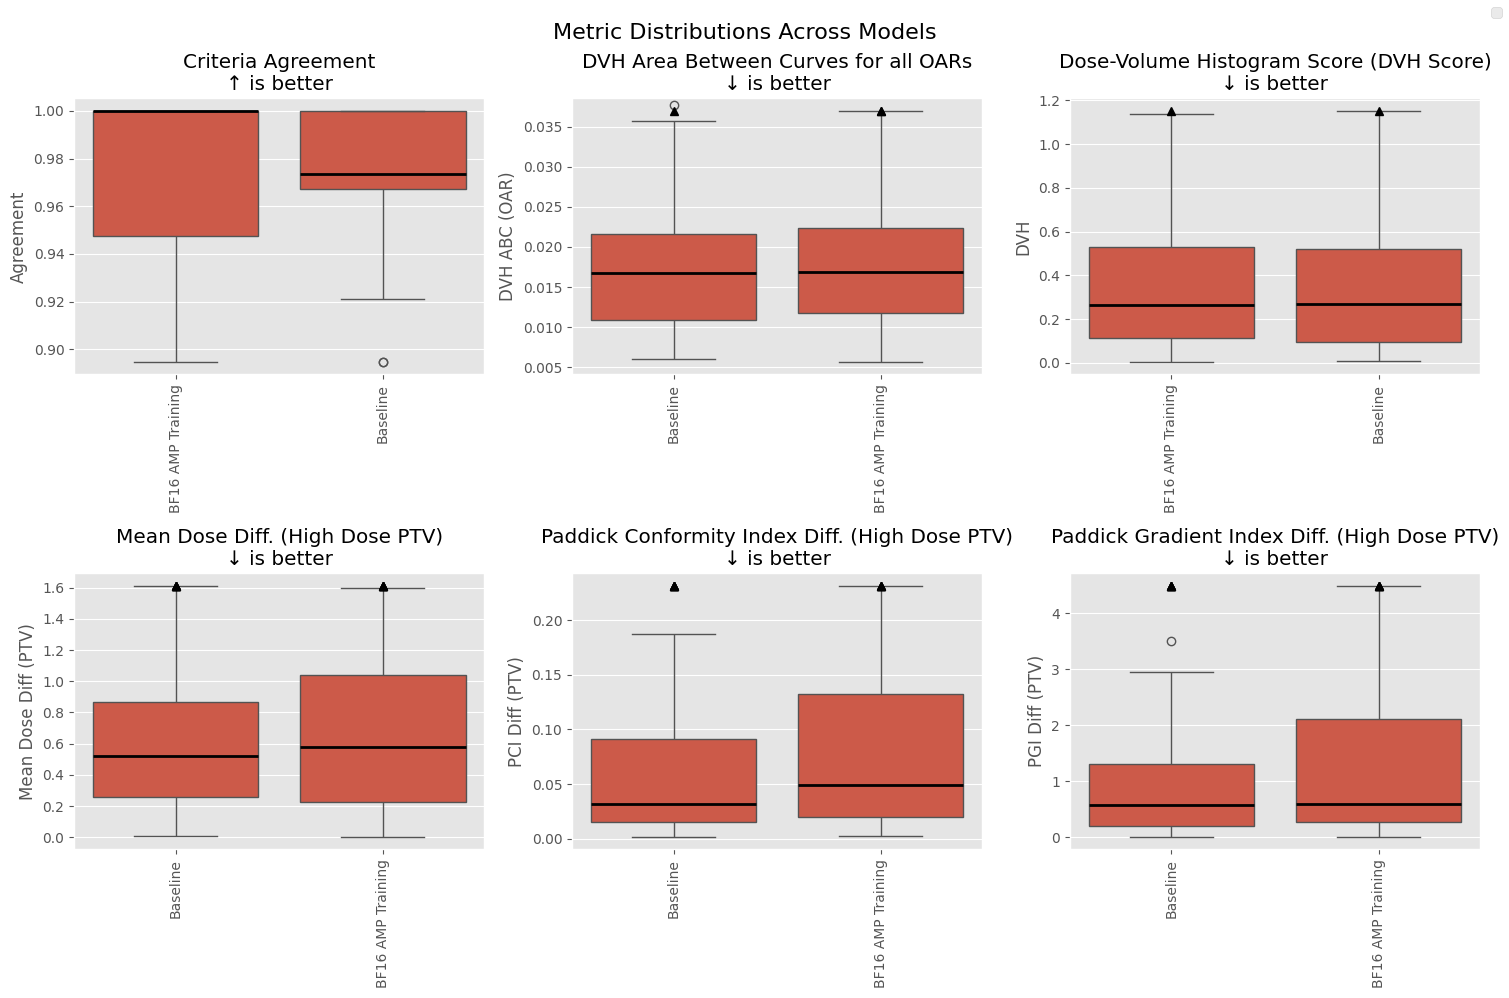

In [14]:
_ = (training_comparison - fp16_train_pred).plot_metric_distributions(METRICS_PRED, sort=True, outliers=False)

# Post-Training Quantization Sampling

In [15]:
sampling_comparison = ModelComparison(
  [baseline_pred, bf16_samp_pred, fp16_samp_pred],
  ['Baseline', 'bfloat16 Sampling', 'float16 Sampling']
)

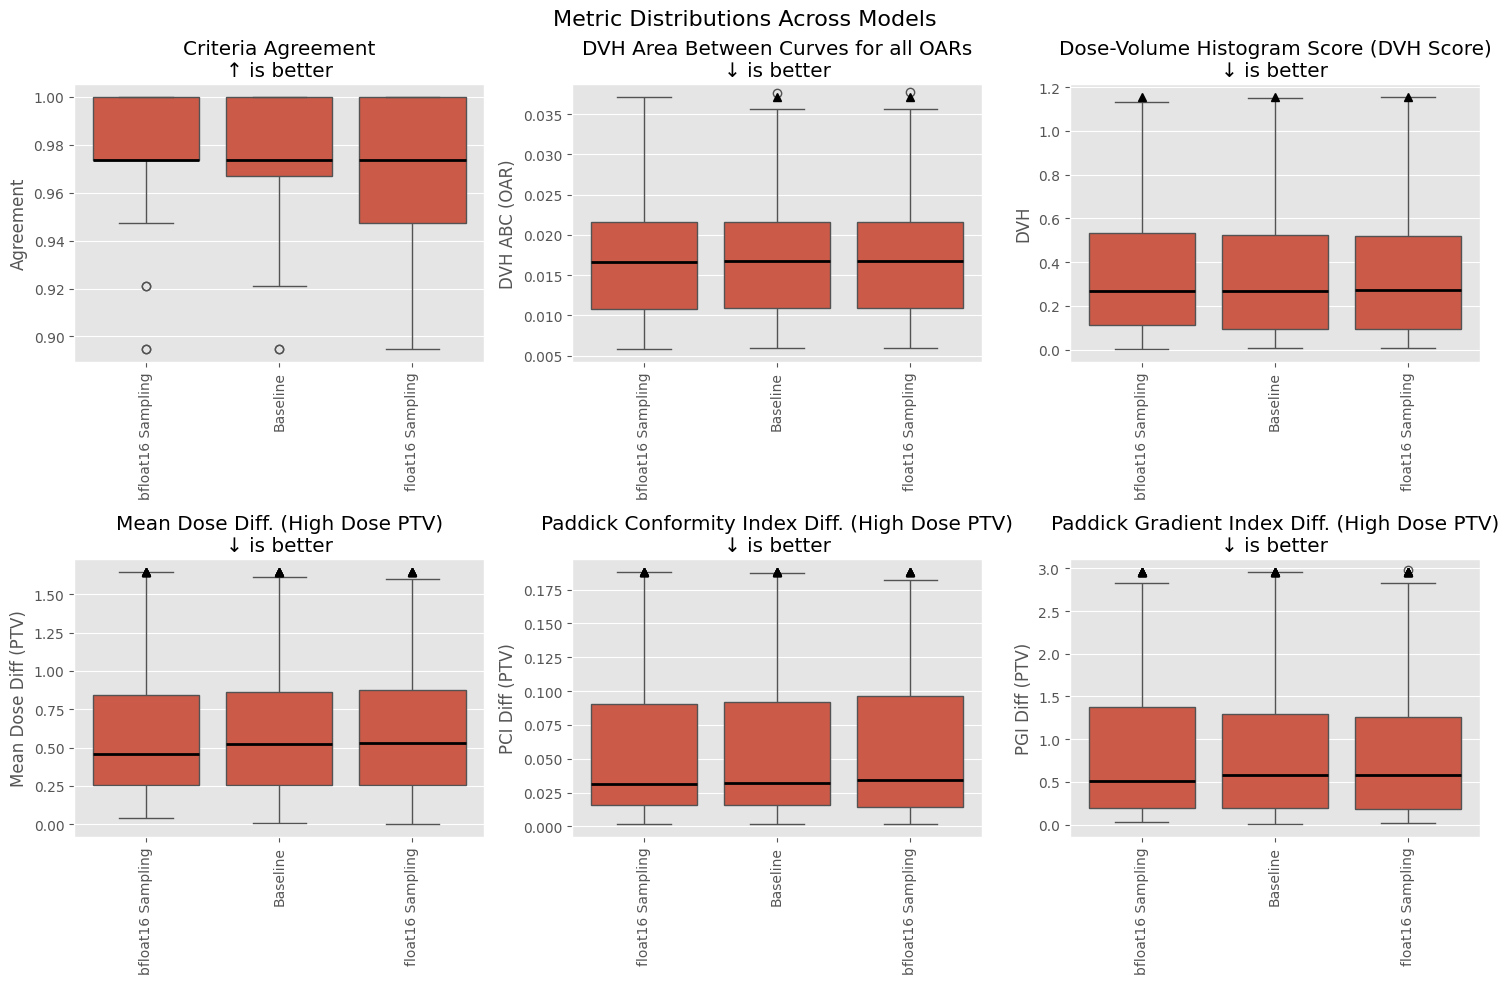

In [18]:
_ = sampling_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=False)

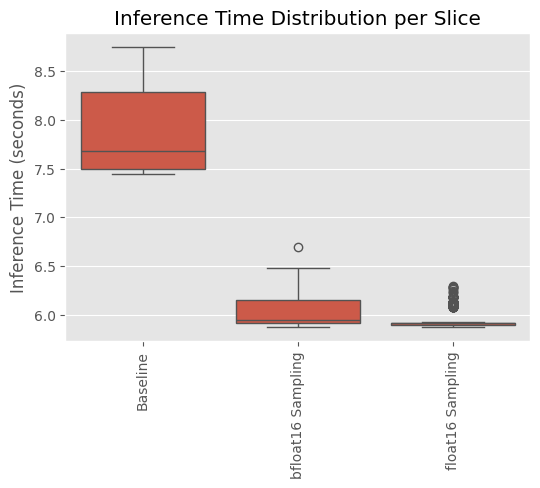

In [20]:
_ = sampling_comparison.plot_inference_times('slice', unit='seconds')

# AMP + Post-Training Quantization

In [6]:
bf16_train_comparison = ModelComparison(
  [bf16_train_pred, bf16_bf16_pred, bf16_fp16_pred],
  ['Baseline', 'bfloat16 Sampling', 'float16 Sampling']
)

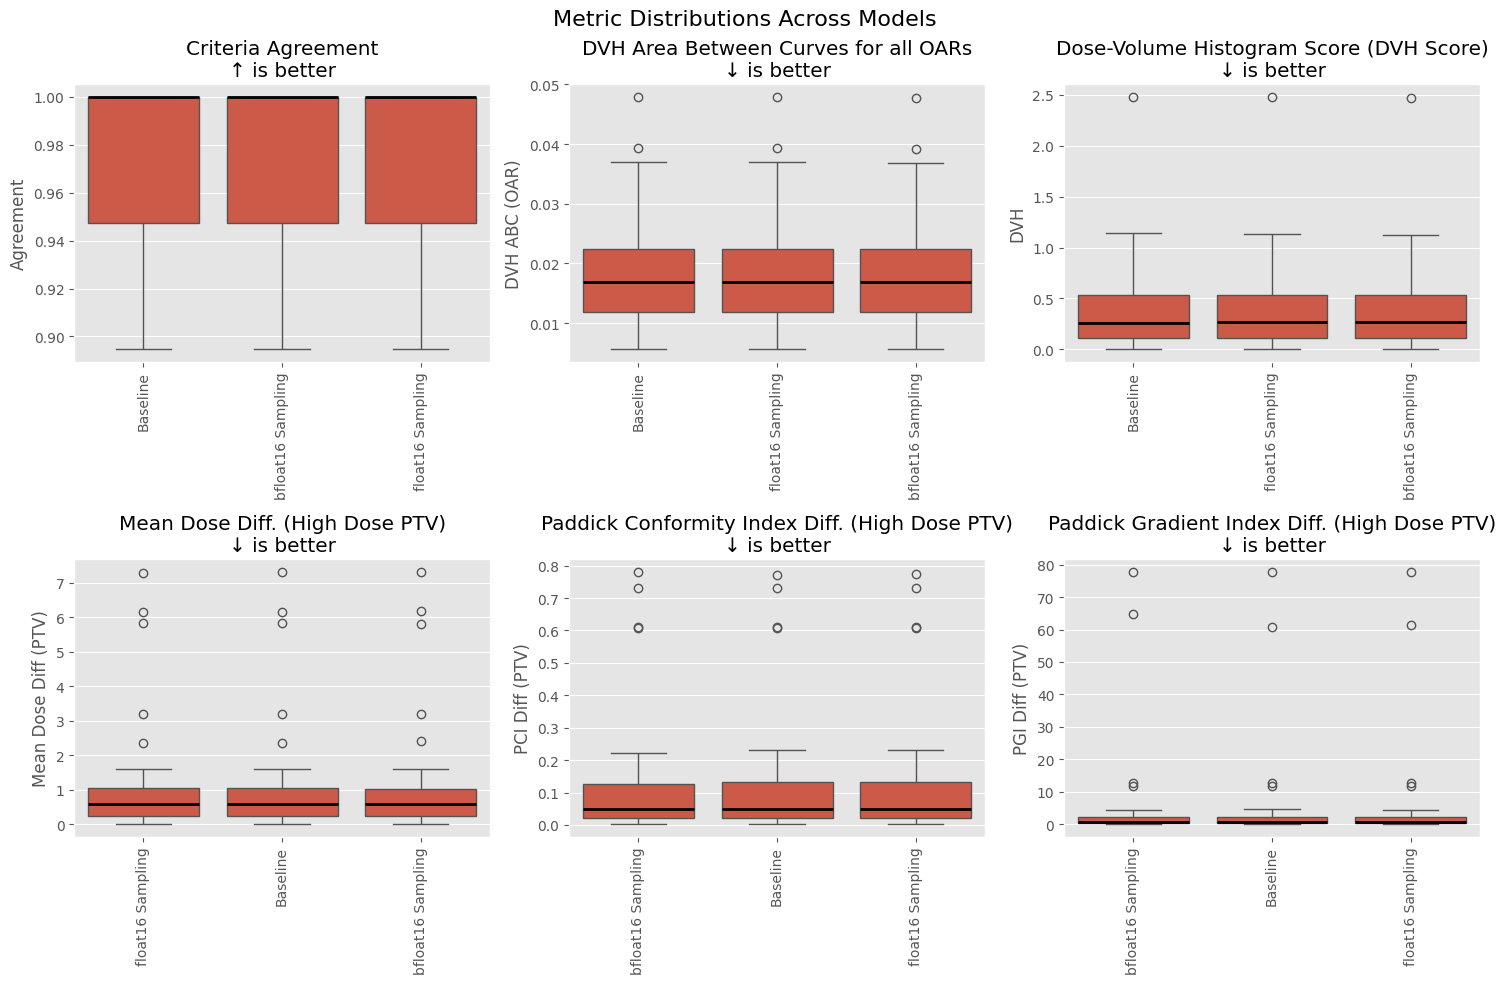

In [7]:
_ = bf16_train_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=True)

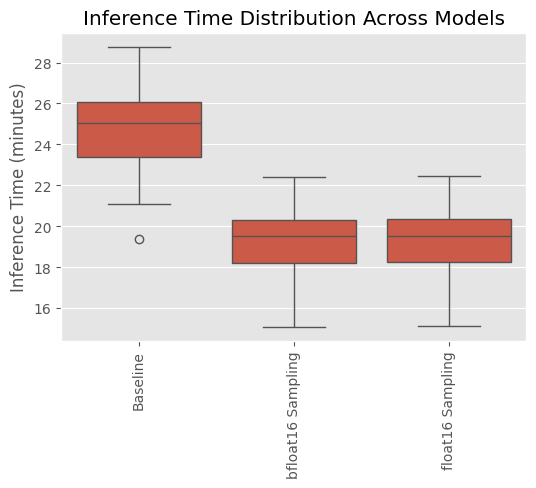

In [8]:
_ = sampling_comparison.plot_inference_times()